In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from pathlib import Path

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
GPU: []


In [2]:
train_split_df = pd.read_csv("../results/train_split.csv")
val_split_df = pd.read_csv("../results/val_split.csv")
test_df = pd.read_csv("../results/test_split.csv")

print("Training:", len(train_split_df))
print("Validation:", len(val_split_df))
print("Test:", len(test_df))

Training: 4694
Validation: 522
Test: 624


In [3]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

In [4]:
def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, label

In [5]:
train_paths = train_split_df["image_path"].values

train_labels = (
    train_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_ds = train_ds.shuffle(
    buffer_size=len(train_split_df),
    seed=42
)

train_ds = train_ds.batch(BATCH_SIZE)
train_ds = train_ds.prefetch(tf.data.AUTOTUNE)

In [6]:
val_paths = val_split_df["image_path"].values

val_labels = (
    val_split_df["label"] == "PNEUMONIA"
).astype(np.float32).values

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.batch(BATCH_SIZE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

In [7]:
test_paths = test_df["image_path"].values

test_labels = (
    test_df["label"] == "PNEUMONIA"
).astype(np.float32).values

test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(BATCH_SIZE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

In [8]:
model = tf.keras.models.load_model(
    "../models/mobilenetv2_baseline.keras"
)

print("Baseline model loaded successfully!")

Baseline model loaded successfully!


In [9]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,829 (8.63 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2,564 (10.02 KB)

In [10]:
# Find the MobileNetV2 base model
for layer in model.layers:
    print(layer.name, layer.trainable)

input_layer_2 True
data_augmentation True
rescaling True
mobilenetv2_1.00_224 False
global_average_pooling2d True
dropout True
dense True


In [11]:
for layer in model.layers:
    print(layer.name, type(layer).__name__)

input_layer_2 InputLayer
data_augmentation Sequential
rescaling Rescaling
mobilenetv2_1.00_224 Functional
global_average_pooling2d GlobalAveragePooling2D
dropout Dropout
dense Dense


In [12]:
base_model = None

for layer in model.layers:
    if isinstance(layer, tf.keras.Model):
        base_model = layer
        break

print("Base model:", base_model.name if base_model else "Not found")

Base model: data_augmentation


In [13]:
base_model.trainable = True

# Freeze the earlier layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep the last 30 layers trainable
for layer in base_model.layers[-30:]:
    layer.trainable = True

print("Total base layers:", len(base_model.layers))
print(
    "Trainable base layers:",
    sum(layer.trainable for layer in base_model.layers)
)

Total base layers: 3
Trainable base layers: 3


In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [15]:
fine_tune_history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


c:\Users\SHIVAMANI\OneDrive\HTML\Deep Learning\AI-Medical-Image-Analysis\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


147/147 ━━━━━━━━━━━━━━━━━━━━ 41s 235ms/step - accuracy: 0.9092 - loss: 0.2276 - precision: 0.9656 - recall: 0.9102 - val_accuracy: 0.9042 - val_loss: 0.2271 - val_precision: 0.9774 - val_recall: 0.8918
Epoch 2/5
147/147 ━━━━━━━━━━━━━━━━━━━━ 34s 210ms/step - accuracy: 0.9210 - loss: 0.2121 - precision: 0.9548 - recall: 0.9381 - val_accuracy: 0.9215 - val_loss: 0.2055 - val_precision: 0.9728 - val_recall: 0.9201
Epoch 3/5
147/147 ━━━━━━━━━━━━━━━━━━━━ 34s 208ms/step - accuracy: 0.9265 - loss: 0.2042 - precision: 0.9483 - recall: 0.9530 - val_accuracy: 0.9253 - val_loss: 0.1984 - val_precision: 0.9729 - val_recall: 0.9253
Epoch 4/5
147/147 ━━━━━━━━━━━━━━━━━━━━ 34s 208ms/step - accuracy: 0.9207 - loss: 0.2051 - precision: 0.9398 - recall: 0.9544 - val_accuracy: 0.9272 - val_loss: 0.1956 - val_precision: 0.9730 - val_recall: 0.9278
Epoch 5/5
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 206ms/step - accuracy: 0.9244 - loss: 0.1977 - precision: 0.9426 - recall: 0.9564 - val_accuracy: 0.9253 - val_loss: 0.

In [16]:
test_results = model.evaluate(
    test_ds,
    verbose=1
)

print("\nFine-tuned Test Results:")

for name, value in zip(model.metrics_names, test_results):
    print(f"{name}: {value:.4f}")

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 188ms/step - accuracy: 0.8381 - loss: 0.3379 - precision: 0.8162 - recall: 0.9564

Fine-tuned Test Results:
loss: 0.3379
compile_metrics: 0.8381


In [17]:
y_true_ft = []
y_prob_ft = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    y_true_ft.extend(labels.numpy().flatten())
    y_prob_ft.extend(predictions.flatten())

y_true_ft = np.array(y_true_ft)
y_prob_ft = np.array(y_prob_ft)

y_pred_ft = (y_prob_ft >= 0.5).astype(int)

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy_ft = accuracy_score(y_true_ft, y_pred_ft)
precision_ft = precision_score(y_true_ft, y_pred_ft)
recall_ft = recall_score(y_true_ft, y_pred_ft)
f1_ft = f1_score(y_true_ft, y_pred_ft)
roc_auc_ft = roc_auc_score(y_true_ft, y_prob_ft)

print(f"Accuracy : {accuracy_ft:.4f}")
print(f"Precision: {precision_ft:.4f}")
print(f"Recall   : {recall_ft:.4f}")
print(f"F1 Score : {f1_ft:.4f}")
print(f"ROC-AUC  : {roc_auc_ft:.4f}")

Accuracy : 0.8381
Precision: 0.8162
Recall   : 0.9564
F1 Score : 0.8808
ROC-AUC  : 0.9436


In [19]:
baseline_results = {
    "Accuracy": 0.8862,
    "Precision": 0.8978,
    "Recall": 0.9231,
    "F1 Score": 0.9102,
    "ROC-AUC": 0.9460
}

fine_tuned_results = {
    "Accuracy": accuracy_ft,
    "Precision": precision_ft,
    "Recall": recall_ft,
    "F1 Score": f1_ft,
    "ROC-AUC": roc_auc_ft
}

comparison = pd.DataFrame(
    [baseline_results, fine_tuned_results],
    index=["Baseline", "Fine-Tuned"]
)

comparison

,Accuracy,Precision,Recall,F1 Score,ROC-AUC
Baseline,0.886200,0.897800,0.92310,0.910200,0.946000
Fine-Tuned,0.838141,0.816193,0.95641,0.880756,0.943612


[[150  84]
 [ 17 373]]


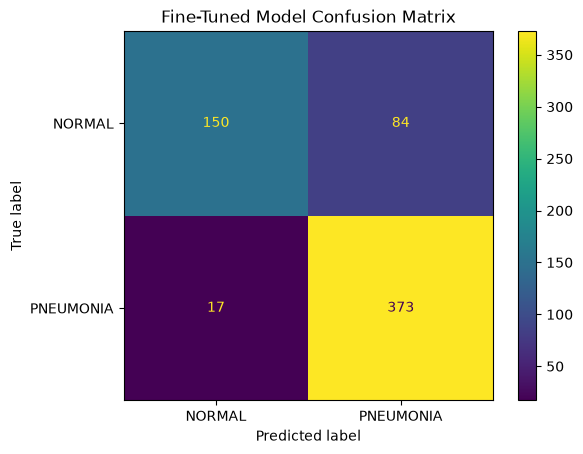

In [20]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_ft = confusion_matrix(y_true_ft, y_pred_ft)

print(cm_ft)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=["NORMAL", "PNEUMONIA"]
)

disp.plot()
plt.title("Fine-Tuned Model Confusion Matrix")
plt.show()

In [21]:
model.save("../models/mobilenetv2_finetuned.keras")

print("Fine-tuned model saved successfully!")

Fine-tuned model saved successfully!
